## 形式化描述
多臂老虎机问题可以表示为一个元组`{A, R}` ，其中：
- `A`为动作集合，其中一个动作表示拉动一个拉杆。若多臂老虎机一共有`K`根拉杆，那动作空间就是集合{a1, a2, ... ,ak}；
- `R`为奖励概率分布，拉动每一根拉杆的动作都对应一个奖励概率分布，不同拉杆的奖励分布通常是不同的。

## 重要定义
- 引入懊悔（regret）概念。懊悔定义为拉动当前拉杆的动作与最优拉杆的期望奖励差。
- 累积懊悔（cumulative regret）即操作`T`次拉杆后累积的懊悔总量。
- MAB 问题的目标为最大化累积奖励，等价于最小化累积懊悔

In [8]:
import numpy as np
import matplotlib.pyplot as plt

class BernoulliBandit:
    '''伯努利老虎机，输入K表示臂数'''
    def __init__(self, K):
        self.K = K
        self.probs = np.random.uniform(size = K)  # 随机生成K个0到1之间的概率作为每个臂的成功概率
        # 概率
        self.best_idx = np.argmax(self.probs)  # 最优臂的索引
        self.best_prob = self.probs[self.best_idx]  # 最优臂的成功概率

    def step(self, k):
        '''执行一次动作，输入k表示选择的臂，返回奖励1或0'''
        if np.random.rand() < self.probs[k]:  # 根据选择的臂的成功概率决定奖励
            return 1
        else:
            return 0
        
np.random.seed(1)  # 设置随机种子以保证结果可复现
K = 10
bandit_10_arm = BernoulliBandit(K)  # 创建一个10臂的老虎机实例
print("随机生成一个%d臂的老虎机" % K)
print("获奖概率最大的臂索引：%d，成功概率：%.4f" % (bandit_10_arm.best_idx, bandit_10_arm.best_prob))

随机生成一个10臂的老虎机
获奖概率最大的臂索引：1，成功概率：0.7203


接下来我们用一个 Solver 基础类来实现上述的多臂老虎机的求解方案。根据前文的算法流程，我们需要实现下列函数功能：根据策略选择动作、根据动作获取奖励、更新期望奖励估值、更新累积懊悔和计数。
在下面MAB算法框架中，将根据策略选择动作、根据动作获取奖励和更新期望奖励估值放在 run_one_step() 函数中，由每个继承 Solver 类的策略具体实现。而更新累积懊悔和计数则直接放在主循环 run() 中。

In [ ]:
class Solver:
    """ 多臂老虎机算法基本框架 """
    def __init__(self, bandit):
        self.bandit = bandit #老虎机实例
        self.counts = np.zeros(self.bandit.K)  # 每根拉杆的尝试次数
        self.regret = 0.  # 当前步的累积懊悔
        self.actions = []  # 维护一个列表,记录每一步的动作
        self.regrets = []  # 维护一个列表,记录每一步的累积懊悔

    def update_regret(self, k):
        # 计算累积懊悔并保存,k为本次动作选择的拉杆的编号
        self.regret += self.bandit.best_prob - self.bandit.probs[k]
        self.regrets.append(self.regret)

    def run_one_step(self):
        # 返回当前动作选择哪一根拉杆,由每个具体的策略实现
        raise NotImplementedError

    def run(self, num_steps):
        # 运行一定次数,num_steps为总运行次数
        for _ in range(num_steps):
            k = self.run_one_step()
            self.counts[k] += 1
            self.actions.append(k)
            self.update_regret(k)

### 探索与平衡的利用
- 探索（exploration）是指尝试拉动更多可能的拉杆，这根拉杆不一定会获得最大的奖励，但这种方案能够摸清楚所有拉杆的获奖情况。例如，对于一个 10 臂老虎机，我们要把所有的拉杆都拉动一下才知道哪根拉杆可能获得最大的奖励。
- 利用（exploitation）是指拉动已知期望奖励最大的那根拉杆，由于已知的信息仅仅来自有限次的交互观测，所以当前的最优拉杆不一定是全局最优的。例如，对于一个 10 臂老虎机，我们只拉动过其中 3 根拉杆，接下来就一直拉动这 3 根拉杆中期望奖励最大的那根拉杆，但很有可能期望奖励最大的拉杆在剩下的 7 根当中，即使我们对 10 根拉杆各自都尝试了 20 次，发现 5 号拉杆的经验期望奖励是最高的，但仍然存在着微小的概率—另一根 6 号拉杆的真实期望奖励是比 5 号拉杆更高的。

#### ϵ-贪心算法
完全贪婪算法即在每一时刻采取期望奖励估值最大的动作（拉动拉杆），这就是纯粹的利用，而没有探索，所以我们通常需要对完全贪婪算法进行一些修改，其中比较经典的一种方法为 ϵ-贪婪（ ϵ-Greedy）算法。 ϵ-贪婪算法在完全贪婪算法的基础上添加了噪声，每次以概率`1-ϵ` 选择以往经验中期望奖励估值最大的那根拉杆（利用），以概率`ϵ`  随机选择一根拉杆（探索）

In [ ]:
class EpsilonGreedy(Solver):
    """ epsilon贪婪算法,继承Solver类 """
    def __init__(self, bandit, epsilon=0.01, init_prob=1.0):
        super(EpsilonGreedy, self).__init__(bandit) #调用父类的构造函数初始化基本属性
        self.epsilon = epsilon #探索率，表示以epsilon的概率随机选择一根拉杆，以1-epsilon的概率选择当前期望奖励估值最大的拉杆
        #初始化拉动所有拉杆的期望奖励估值
        self.estimates = np.array([init_prob] * self.bandit.K)

    def run_one_step(self):
        if np.random.random() < self.epsilon:
            k = np.random.randint(0, self.bandit.K)  # 随机选择一根拉杆
        else:
            k = np.argmax(self.estimates)  # 选择期望奖励估值最大的拉杆
        r = self.bandit.step(k)  # 得到本次动作的奖励
        self.estimates[k] += 1. / (self.counts[k] + 1) * (r - self.estimates[k])
        return k

epsilon-贪婪算法的累积懊悔为： 25.526630933945313


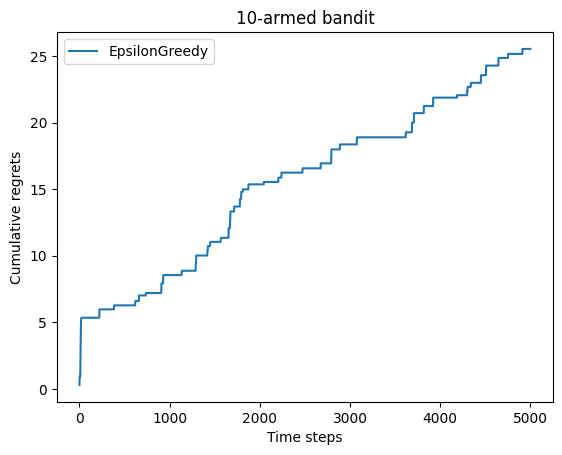

In [11]:
def plot_results(solvers, solver_names):
    """生成累积懊悔随时间变化的图像。输入solvers是一个列表,列表中的每个元素是一种特定的策略。
    而solver_names也是一个列表,存储每个策略的名称"""
    for idx, solver in enumerate(solvers):
        time_list = range(len(solver.regrets))
        plt.plot(time_list, solver.regrets, label=solver_names[idx])
    plt.xlabel('Time steps')
    plt.ylabel('Cumulative regrets')
    plt.title('%d-armed bandit' % solvers[0].bandit.K)
    plt.legend()
    plt.show()


np.random.seed(1)
epsilon_greedy_solver = EpsilonGreedy(bandit_10_arm, epsilon=0.01)
epsilon_greedy_solver.run(5000)
print('epsilon-贪婪算法的累积懊悔为：', epsilon_greedy_solver.regret)
plot_results([epsilon_greedy_solver], ["EpsilonGreedy"])

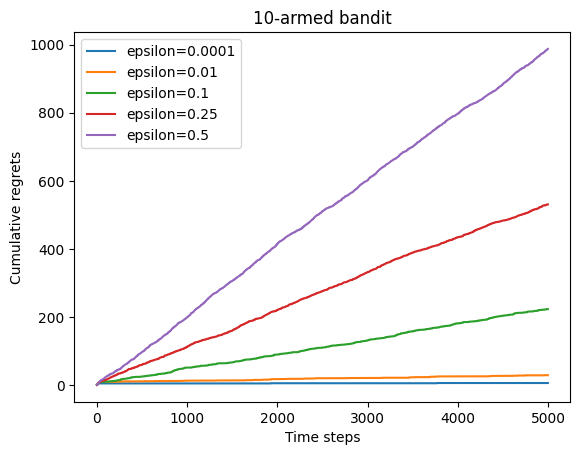

In [12]:
np.random.seed(0)
epsilons = [1e-4, 0.01, 0.1, 0.25, 0.5]
epsilon_greedy_solver_list = [
    EpsilonGreedy(bandit_10_arm, epsilon=e) for e in epsilons
]
epsilon_greedy_solver_names = ["epsilon={}".format(e) for e in epsilons]
for solver in epsilon_greedy_solver_list:
    solver.run(5000)

plot_results(epsilon_greedy_solver_list, epsilon_greedy_solver_names)

通过实验结果可以发现，基本上无论 ϵ 取值多少，累积懊悔都是线性增长的。在这个例子中，随着 ϵ 的增大，累积懊悔增长的速率也会增大。 接下来我们尝试 ϵ 值随时间衰减的 ϵ-贪婪算法，采取的具体衰减形式为反比例衰减

epsilon值衰减的贪婪算法的累积懊悔为： 10.114334931260183


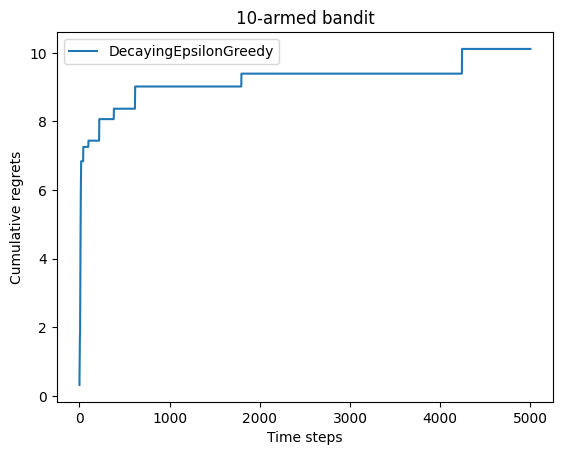

In [13]:
class DecayingEpsilonGreedy(Solver):
    """ epsilon值随时间衰减的epsilon-贪婪算法,继承Solver类 """
    def __init__(self, bandit, init_prob=1.0):
        super(DecayingEpsilonGreedy, self).__init__(bandit)
        self.estimates = np.array([init_prob] * self.bandit.K)
        self.total_count = 0

    def run_one_step(self):
        self.total_count += 1
        if np.random.random() < 1 / self.total_count:  # epsilon值随时间衰减
            k = np.random.randint(0, self.bandit.K)
        else:
            k = np.argmax(self.estimates)

        r = self.bandit.step(k)
        self.estimates[k] += 1. / (self.counts[k] + 1) * (r - self.estimates[k])

        return k


np.random.seed(1)
decaying_epsilon_greedy_solver = DecayingEpsilonGreedy(bandit_10_arm)
decaying_epsilon_greedy_solver.run(5000)
print('epsilon值衰减的贪婪算法的累积懊悔为：', decaying_epsilon_greedy_solver.regret)
plot_results([decaying_epsilon_greedy_solver], ["DecayingEpsilonGreedy"])